# Discharge follow-up prioritization: model experiments

**Question:** If an outreach team can contact only 10% of eligible discharges, how many recorded early readmissions can a predictive model identify?

This notebook walks through the actual project code and measured results, including logistic regression, XGBoost, and bagged decision trees. It compares a fixed validation split, patient-group cross-validation, and adding bagging.

**Reading the saved run:** leave `RUN_TRAINING = False`. The notebook shows saved results from the real training run, without repeating 15 cross-validation fits. Set it to `True` and run every cell in order to train again.

**Cloud status:** BigQuery preparation, Vertex training, a real endpoint prediction, and undeployment completed on October 14, 2026. This notebook retains the local evaluation outputs; cloud results and their provenance are saved separately in `artifacts/vertex/cloud_results.json` and `evidence_provenance.json`. See `02_gcp_workflow.ipynb` for the cloud stages.

Data: [UCI Diabetes 130-US Hospitals (1999–2008)](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008), Clore, Cios, DeShazo & Strack (2014), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Historical diabetes-associated encounters; this is a retrospective learning prototype, not clinical validation.

## 1. Environment and project paths
Select **Readmission GCP (Python 3.12)** or this project's **`.venv/bin/python`** as the notebook kernel, restart it, and run all cells in order. The system Python 3.9.6 kernel does not match this project's dependencies. `scripts/configure_kernel.py` configures the project kernel, including the Mac OpenMP library. The introduction and other explanatory cells are Markdown cells, not Python cells.

In [1]:
from pathlib import Path
import os
import sys
if sys.version_info < (3, 11):
    raise RuntimeError(f"Current kernel is Python {sys.version.split()[0]}. Select this project's .venv/bin/python (Python 3.12), restart the kernel, then Run All. Do not use the system Python 3.9.6 kernel.")
ROOT = Path.cwd()
if not (ROOT / "readmission").exists() and (ROOT / "readmission-gcp/readmission").exists():
    ROOT = ROOT / "readmission-gcp"
assert (ROOT / "readmission").exists(), "Open the notebook from the readmission-gcp folder."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".matplotlib"))
RUN_TRAINING = True
data_path = Path("data/processed/features.csv")
output_dir = Path("artifacts")
execution = "local"
print("Mode:", "new training run" if RUN_TRAINING else "inspect saved training results")
print("Project folder:", ROOT)
print("Kernel interpreter:", sys.executable)
print("Python version:", sys.version.split()[0])

Mode: new training run
Project folder: [project directory]
Kernel interpreter: [project directory]/.venv/bin/python
Python version: 3.12.14


In [2]:
"""Same training entry point runs locally or in a Vertex AI custom job."""
import argparse
import json
import os
import platform
import shutil
import tempfile
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import BaggingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from readmission.evaluate import metrics, subgroup_audit, top_mask
from readmission.features import AUDIT, CATEGORICAL, FEATURES, MISSING, NUMERIC, SEED, patient_split



import matplotlib.pyplot as plt
from IPython.display import display

## 2. Inspect the source and define the cohort
The outcome is `readmitted == '<30'`; `'>30'` and `'NO'` are negative. We score at discharge, so features recorded during the stay can be used. Only discharge dispositions **1 (home), 6 (home health), and 8 (Home IV provider)** are eligible. The original mapping file confirms these meanings.

Patient and encounter IDs are used for grouping and audit only. Race and sex are retained for subgroup checks but are not prediction inputs. Age remains an input. Weight, payer code, medical specialty, and two constant medication columns are omitted.

In [3]:
from readmission.prepare import download, prepare
raw_path = Path("data/raw/diabetic_data.csv")
if not raw_path.exists():
    download(raw_path.parent)
raw = pd.read_csv(raw_path, dtype=str, keep_default_na=False)
display(raw[FEATURES + ["readmitted"]].head())
print("Raw encounters:", len(raw))
_, quality = prepare(raw_path, "data/processed")
display(pd.DataFrame(quality["splits"]).T)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age,admission_type_id,...,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,1,41,0,1,0,0,0,1,[0-10),6,...,No,No,No,No,No,No,No,No,No,NO
1,3,59,0,18,0,0,0,9,[10-20),1,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,2,11,5,13,2,0,1,6,[20-30),1,...,No,No,No,No,No,No,No,No,Yes,NO
3,2,44,1,16,0,0,0,7,[30-40),1,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,1,51,0,8,0,0,0,5,[40-50),1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


Raw encounters: 101766


{
  "source_rows": 101766,
  "eligible_rows": 73244,
  "positive_rate": 0.09905248211457594,
  "splits": {
    "test": {
      "encounters": 10858,
      "patients": 8181,
      "positive_rate": 0.10029471357524405
    },
    "train": {
      "encounters": 51325,
      "patients": 38438,
      "positive_rate": 0.09911349245007306
    },
    "validation": {
      "encounters": 11061,
      "patients": 8313,
      "positive_rate": 0.0975499502757436
    }
  }
}


,encounters,patients,positive_rate
test,10858.0,8181.0,0.100295
train,51325.0,38438.0,0.099113
validation,11061.0,8313.0,0.097550


## 3. Hold out patients, not random visits
A deterministic SHA256 bucket assigns roughly 70% of patients to training, 15% to validation, and 15% to testing. The training group alone participates in cross-validation. The validation group calibrates probabilities; the original no-CV workflow also selects its model there. The same final test group evaluates all workflows.

This is a patient-group split. It cannot establish performance on future years or unseen hospitals because encounter dates and hospital identifiers are not provided.

In [4]:
output_dir = Path(output_dir)
output_dir.mkdir(parents=True, exist_ok=True)
frame = pd.read_csv(data_path, dtype={c: str for c in AUDIT + CATEGORICAL}, keep_default_na=False)
if frame.encounter_id.duplicated().any():
    raise ValueError("Encounter IDs must be unique.")
expected = frame.patient_nbr.map(patient_split)
if not (expected == frame.split).all():
    raise ValueError("Split assignments do not match the patient-group contract.")
# Numeric ordering makes equal-score capacity tie-breaking reproducible after BQ export.
frame = frame.assign(_order=pd.to_numeric(frame.encounter_id)).sort_values("_order").drop(columns="_order").reset_index(drop=True)
train_frame = frame[frame.split == "train"]
validation = frame[frame.split == "validation"]
test = frame[frame.split == "test"]
if any(part.label.nunique() != 2 for part in [train_frame, validation, test]):
    raise ValueError("All partitions must contain both classes.")
display(pd.DataFrame({name: {'encounters': len(part), 'patients': part.patient_nbr.nunique(), 'early_readmission_rate': part.label.mean()} for name, part in frame.groupby('split')}).T)
assert frame.groupby('patient_nbr')['split'].nunique().max() == 1
print('Patient overlap between partitions: 0')

,encounters,patients,early_readmission_rate
test,10858.0,8181.0,0.100295
train,51325.0,38438.0,0.099113
validation,11061.0,8313.0,0.097550


Patient overlap between partitions: 0


## 4. Define preprocessing and the three models
Numeric counts are imputed and standardized. Categorical values are one-hot encoded; rare categories are grouped. Each cross-validation fold fits its own transformations on its training portion, avoiding preprocessing leakage.

**Logistic regression:** the simple baseline, with regularization (`C=0.5`).

**XGBoost:** sequential boosted trees, with fixed parameters for this first comparison.

**Bagging:** 100 decision trees. Each tree sees a bootstrap sample containing 80% of training rows and a random 80% of encoded features; predicted probabilities are averaged. Tree depth and leaf size limit complexity. Bootstrap sampling happens inside the training fold; patient groups remain separated from fold holdout data.

In [5]:
def preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                               ("scale", StandardScaler())]), NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=25), CATEGORICAL),
    ], remainder="drop", sparse_threshold=1.0)

In [6]:
def model_candidates():
    return {
        "logistic_regression": LogisticRegression(C=0.5, max_iter=2000, random_state=SEED),
        "xgboost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                  subsample=0.85, colsample_bytree=0.85, reg_lambda=5,
                                  min_child_weight=20, tree_method="hist", eval_metric="logloss",
                                  random_state=SEED, n_jobs=2),
        "bagged_trees": BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=8, min_samples_leaf=30, random_state=SEED),
            n_estimators=100, max_samples=0.8, max_features=0.8,
            bootstrap=True, random_state=SEED, n_jobs=2,
        ),
    }
display(pd.DataFrame({'model': list(model_candidates()), 'estimator': [str(m) for m in model_candidates().values()]}))

,model,estimator
0,logistic_regression,"LogisticRegression(C=0.5, max_iter=2000, rando..."
1,xgboost,"XGBClassifier(base_score=None, booster=None, c..."
2,bagged_trees,BaggingClassifier(estimator=DecisionTreeClassi...


## 5. Five-fold patient-group cross-validation
Each training patient appears in the holdout portion of exactly one fold. All three models use the same folds. We select using mean **average precision**, a summary of the precision–recall curve appropriate for the minority readmission outcome. Fold standard deviation describes variability; it is not a confidence interval.

In [7]:
def cross_validate_models(train_frame, n_splits=5):
    """Fit preprocessing within each fold; only the training partition participates."""
    from sklearn.base import clone
    folds = list(GroupKFold(n_splits=n_splits).split(
        train_frame[FEATURES], train_frame.label, groups=train_frame.patient_nbr))
    results = []
    for name, estimator in model_candidates().items():
        for number, (fit_index, holdout_index) in enumerate(folds, start=1):
            fit = train_frame.iloc[fit_index]
            holdout = train_frame.iloc[holdout_index]
            overlap = set(fit.patient_nbr) & set(holdout.patient_nbr)
            if overlap:
                raise ValueError("Patient leakage in cross-validation.")
            pipeline = Pipeline([("features", preprocessor()), ("model", clone(estimator))])
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                pipeline.fit(fit[FEATURES], fit.label)
            scores = pipeline.predict_proba(holdout[FEATURES])[:, 1]
            values = metrics(holdout.label, scores)
            results.append({"model": name, "fold": number, "train_patients": int(fit.patient_nbr.nunique()),
                            "holdout_patients": int(holdout.patient_nbr.nunique()), "patient_overlap": 0,
                            **{key: value for key, value in values.items() if key != "calibration"}})
            print(f"CV {name} fold {number}/{n_splits}: AP={values['average_precision']:.4f}", flush=True)
    rows = pd.DataFrame(results)
    keys = ["average_precision", "roc_auc", "brier_score", "precision_at_capacity", "recall_at_capacity"]
    summary = {name: {key: {"mean": float(group[key].mean()), "std": float(group[key].std(ddof=1))}
                      for key in keys} for name, group in rows.groupby("model")}
    return rows, summary

In [8]:
if RUN_TRAINING:
    cv_rows, cv_summary = cross_validate_models(train_frame)
    cv_rows.to_csv(output_dir / "cross_validation.csv", index=False)
    (output_dir / "cross_validation_summary.json").write_text(json.dumps(cv_summary, indent=2))
else:
    cv_rows = pd.read_csv(output_dir / 'cross_validation.csv')
    cv_summary = json.loads((output_dir / 'cross_validation_summary.json').read_text())
display(cv_rows[['model', 'fold', 'average_precision', 'roc_auc', 'recall_at_capacity', 'patient_overlap']])

CV logistic_regression fold 1/5: AP=0.1853


CV logistic_regression fold 2/5: AP=0.2144


CV logistic_regression fold 3/5: AP=0.1911


CV logistic_regression fold 4/5: AP=0.1959


CV logistic_regression fold 5/5: AP=0.2051


...

CV bagged_trees fold 2/5: AP=0.2254


CV bagged_trees fold 3/5: AP=0.2097


CV bagged_trees fold 4/5: AP=0.1949


CV bagged_trees fold 5/5: AP=0.2091


,model,fold,average_precision,roc_auc,recall_at_capacity,patient_overlap
0,logistic_regression,1,0.185344,0.650627,0.234531,0
1,logistic_regression,2,0.214438,0.654013,0.247664,0
2,logistic_regression,3,0.191074,0.648272,0.234252,0
3,logistic_regression,4,0.195925,0.658308,0.249228,0
4,logistic_regression,5,0.205098,0.659453,0.247082,0
5,xgboost,1,0.189098,0.662192,0.223553,0
6,xgboost,2,0.215806,0.668126,0.249533,0
7,xgboost,3,0.209248,0.674712,0.242126,0
8,xgboost,4,0.197226,0.662676,0.247168,0
9,xgboost,5,0.207643,0.671673,0.255837,0


In [9]:
cv_table = pd.DataFrame([
    {"model": name, "mean_average_precision": values["average_precision"]["mean"],
     "fold_sd": values["average_precision"]["std"],
     "mean_recall_at_10pct": values["recall_at_capacity"]["mean"]}
    for name, values in cv_summary.items()
])
display(cv_table.round(4))

,model,mean_average_precision,fold_sd,mean_recall_at_10pct
0,bagged_trees,0.2058,0.0140,0.2434
1,logistic_regression,0.1984,0.0115,0.2426
2,xgboost,0.2038,0.0106,0.2436


## 6. Fit each candidate on the full training group
These are the actual training commands used by the cloud training script. The saved-run branch shows the measured validation results. No class weighting or oversampling is applied in this first experiment, so probability interpretation remains straightforward.

In [10]:
if RUN_TRAINING:
    candidates = model_candidates()
    fitted, validation_metrics = {}, {}
    for name, estimator in candidates.items():
        print(f"Training {name} on {len(train_frame):,} encounters...", flush=True)
        pipeline = Pipeline([("features", preprocessor()), ("model", estimator)])
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            pipeline.fit(train_frame[FEATURES], train_frame.label)
        fitted[name] = pipeline
        scores = pipeline.predict_proba(validation[FEATURES])[:, 1]
        validation_metrics[name] = metrics(validation.label, scores)
        print(f"Validation average precision: {validation_metrics[name]['average_precision']:.4f}", flush=True)
else:
    result = json.loads((output_dir / 'metrics.json').read_text())
    validation_metrics = result['validation_metrics']
display(pd.DataFrame(validation_metrics).T[['average_precision', 'roc_auc', 'brier_score']])

Training logistic_regression on 51,325 encounters...


Validation average precision: 0.1912


Training xgboost on 51,325 encounters...


Validation average precision: 0.1902


Training bagged_trees on 51,325 encounters...


Validation average precision: 0.1921


,average_precision,roc_auc,brier_score
logistic_regression,0.191185,0.653206,0.085121
xgboost,0.190193,0.664961,0.084796
bagged_trees,0.192119,0.668953,0.084772


## 7. Select models and calibrate probabilities
Compare three workflows on the same inputs and partitions:

1. **No CV, no bagging:** choose logistic regression or XGBoost using fixed validation average precision.
2. **CV, no bagging:** choose between those same models using training-only group CV.
3. **CV + bagging candidate:** allow all three models and choose using that CV score.

Calibration fits a sigmoid to each model's validation log odds. It adjusts probability estimates while preserving ranking. If adding bagging does not improve CV, the selection rule is allowed to keep another model. Test scores do not determine these choices.

In [11]:
def log_odds(scores):
    clipped = np.clip(scores, 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped)).reshape(-1, 1)

def predict_bundle(bundle, frame):
    # Threads avoid spawning extra worker processes inside API/notebook kernels.
    with joblib.parallel_backend("threading", n_jobs=2):
        scores = bundle["pipeline"].predict_proba(frame[FEATURES])[:, 1]
    return bundle["calibrator"].predict_proba(log_odds(scores))[:, 1]

In [12]:
if RUN_TRAINING:
    original_names = ["logistic_regression", "xgboost"]
    workflow_choices = {
        "no_cv_no_bagging": max(original_names, key=lambda name: validation_metrics[name]["average_precision"]),
        "cv_without_bagging": max(original_names, key=lambda name: cv_summary[name]["average_precision"]["mean"]),
        "cv_with_bagging": max(cv_summary, key=lambda name: cv_summary[name]["average_precision"]["mean"]),
    }
    selected = workflow_choices["cv_with_bagging"]
    calibrated_bundles = {}
    for name, pipeline in fitted.items():
        calibration_scores = pipeline.predict_proba(validation[FEATURES])[:, 1]
        calibrator = LogisticRegression(C=1e6, max_iter=1000, random_state=SEED)
        calibrator.fit(log_odds(calibration_scores), validation.label)
        if calibrator.coef_[0, 0] <= 0:
            raise ValueError("Calibration reversed risk ranking; inspect model before exporting.")
        calibrated_bundles[name] = {"pipeline": pipeline, "calibrator": calibrator,
                                   "model_name": name, "features": FEATURES, "schema_version": 1}
    bundle = calibrated_bundles[selected]
    calibrator = bundle["calibrator"]
    joblib.dump(bundle, output_dir / "model.joblib")
else:
    workflow_choices = {key: value['selected_model'] for key, value in result['workflow_comparison'].items()}
    bundle = joblib.load(output_dir / 'model.joblib')
    selected = bundle['model_name']
print('Workflow choices:', workflow_choices)
print('Final saved model:', selected)

Workflow choices: {'no_cv_no_bagging': 'logistic_regression', 'cv_without_bagging': 'xgboost', 'cv_with_bagging': 'bagged_trees'}
Final saved model: bagged_trees


## 8. Evaluate the reserved test group and save evidence
**Recall at 10%:** fraction of recorded readmissions captured by selecting the highest-risk 10% of discharges.

**Precision at 10%:** fraction of selected discharges that actually had a recorded early readmission.

**Lift:** selected-group readmission rate divided by the overall test rate. Random outreach captures roughly 10% of readmissions in expectation.

**Brier score:** probability prediction error; lower is better. ROC AUC and average precision summarize discrimination. Model comparisons are point estimates and do not demonstrate statistically significant superiority.

The test outcome is historical; identifying risk does not establish that outreach would prevent a readmission. An initial two-model run preceded the user-requested CV/bagging expansion. No test results were used to tune settings.

In [13]:
if RUN_TRAINING:
    # Test data is first scored after model choice and calibration are frozen.
    test_metrics = {name: metrics(test.label, model.predict_proba(test[FEATURES])[:, 1]) for name, model in fitted.items()}
    calibrated = predict_bundle(bundle, test)
    test_metrics["selected_calibrated"] = metrics(test.label, calibrated)
    workflow_comparison = {
        workflow: {"selected_model": name,
                   "selection": "fixed validation average precision" if workflow == "no_cv_no_bagging" else "training-only five-fold patient-group CV average precision",
                   "test_metrics": metrics(test.label, predict_bundle(calibrated_bundles[name], test))}
        for workflow, name in workflow_choices.items()
    }
    (output_dir / "workflow_comparison.json").write_text(json.dumps(workflow_comparison, indent=2))
    prevalence = float(train_frame.label.mean())
    test_metrics["constant_training_prevalence"] = metrics(test.label, np.full(len(test), prevalence))
    scored = test[AUDIT + ["age", "label"]].copy()
    scored["predicted_risk"] = calibrated
    scored["selected_for_follow_up"] = top_mask(calibrated)
    scored.to_csv(output_dir / "test_predictions.csv", index=False)
    audit = subgroup_audit(test, calibrated)
    (output_dir / "subgroup_audit.json").write_text(json.dumps(audit, indent=2))
    sample = test.iloc[[0]][FEATURES].to_dict(orient="records")
    (output_dir / "sample_request.json").write_text(json.dumps({"instances": sample}, indent=2))
    (output_dir / "sample_prediction.json").write_text(json.dumps({"predictions": [{"readmission_risk": float(calibrated[0]), "model": selected}]}, indent=2))
    quality_file = Path(data_path).parent / "data_quality.json"
    if quality_file.exists():
        shutil.copy2(quality_file, output_dir / "data_quality.json")
    result = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(), "execution": execution,
        "cloud_status": "not_applicable_local_run" if execution == "local" else "vertex_training_run",
        "selected_model": selected, "selection_metric": "five-fold patient-group CV mean average precision on training data",
        "cross_validation": cv_summary,
        "workflow_comparison": workflow_comparison,
        "validation_metrics": validation_metrics, "test_metrics": test_metrics,
        "features": FEATURES, "training_encounters": len(train_frame),
        "validation_encounters": len(validation), "test_encounters": len(test),
        "patient_overlap_between_splits": 0,
        "versions": {"python": platform.python_version(), "numpy": np.__version__,
                     "pandas": pd.__version__, "sklearn": sklearn.__version__, "xgboost": xgboost.__version__},
        "calibration": {"method": "sigmoid on validation log odds", "slope": float(calibrator.coef_[0, 0]),
                        "intercept": float(calibrator.intercept_[0])},
        "limitations": [
            "Historical 1999–2008 data; results do not establish current clinical usefulness.",
            "Patient-group holdout, not temporal or hospital holdout; encounter dates and hospital IDs are unavailable.",
            "Only diabetes-associated encounters discharged home or with home services are included.",
            "The target is recorded early readmission, not necessarily avoidable or captured across all hospitals.",
            "Outreach prioritization is evaluated retrospectively; reduced readmissions are not demonstrated.",
            "Model selection used five-fold training-group CV; validation data was reserved for calibration.",
            "Group differences are descriptive and do not certify fairness; small samples are flagged.",
        ],
    }
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2))
    from readmission.report import render
    render(output_dir)
    print(json.dumps({"selected_model": selected, "test": test_metrics["selected_calibrated"]}, indent=2), flush=True)
else:
    result = json.loads((output_dir / 'metrics.json').read_text())
    workflow_comparison = result['workflow_comparison']
    test_metrics = result['test_metrics']
print('Run timestamp:', result['created_at_utc'])
print('Execution environment:', result['execution'])

{
  "selected_model": "bagged_trees",
  "test": {
    "n": 10858,
    "positive_count": 1089,
    "positive_rate": 0.10029471357524405,
    "roc_auc": 0.6588989871730265,
    "average_precision": 0.20489052031614818,
    "brier_score": 0.08636139518716301,
    "outreach_count": 1086,
    "capacity_fraction": 0.1,
    "readmissions_in_top_capacity": 272,
    "precision_at_capacity": 0.2504604051565378,
    "recall_at_capacity": 0.2497704315886134,
    "lift_at_capacity": 2.4972443335075183,
    "calibration": [
      {
        "predicted": 0.047252793212426536,
        "observed": 0.04788213627992634
      },
      {
        "predicted": 0.05468075169183308,
        "observed": 0.052486187845303865
      },
      {
        "predicted": 0.060962230448589415,
        "observed": 0.06721915285451197
      },
      {
        "predicted": 0.06712410688801165,
        "observed": 0.0728110599078341
      },
      {
        "predicted": 0.07302835480645506,
        "observed": 0.06721915285451

Run timestamp: 2026-10-14T03:29:01.105912+00:00
Execution environment: local


In [14]:
comparison = pd.DataFrame([
    {"workflow": workflow, "chosen_model": item["selected_model"],
     **{metric: item["test_metrics"][metric] for metric in
        ["average_precision", "roc_auc", "precision_at_capacity", "recall_at_capacity", "brier_score", "lift_at_capacity"]}}
    for workflow, item in workflow_comparison.items()
])
display(comparison.round(4))
print("Same test patients, features, capacity, and calibration method for every workflow.")
display(pd.DataFrame(test_metrics).T[["average_precision", "roc_auc", "precision_at_capacity", "recall_at_capacity", "brier_score"]].round(4))

,workflow,chosen_model,average_precision,roc_auc,precision_at_capacity,recall_at_capacity,brier_score,lift_at_capacity
0,no_cv_no_bagging,logistic_regression,0.2020,0.6532,0.2311,0.2305,0.0867,2.3044
1,cv_without_bagging,xgboost,0.2042,0.6641,0.2541,0.2534,0.0864,2.5340
2,cv_with_bagging,bagged_trees,0.2049,0.6589,0.2505,0.2498,0.0864,2.4972


Same test patients, features, capacity, and calibration method for every workflow.


,average_precision,roc_auc,precision_at_capacity,recall_at_capacity,brier_score
logistic_regression,0.20198,0.653207,0.231123,0.230487,0.086784
xgboost,0.204188,0.664147,0.254144,0.253444,0.086336
bagged_trees,0.204891,0.658899,0.25046,0.24977,0.086497
selected_calibrated,0.204891,0.658899,0.25046,0.24977,0.086361
constant_training_prevalence,0.100295,0.5,0.105893,0.105601,0.090237


## 9. Visual comparison and calibration
The first chart shows variation across the five training folds. The second compares the three workflows on the same test group. A cross-validation choice can change the selected model, but CV does not change the prediction formula of a model that is otherwise identical.

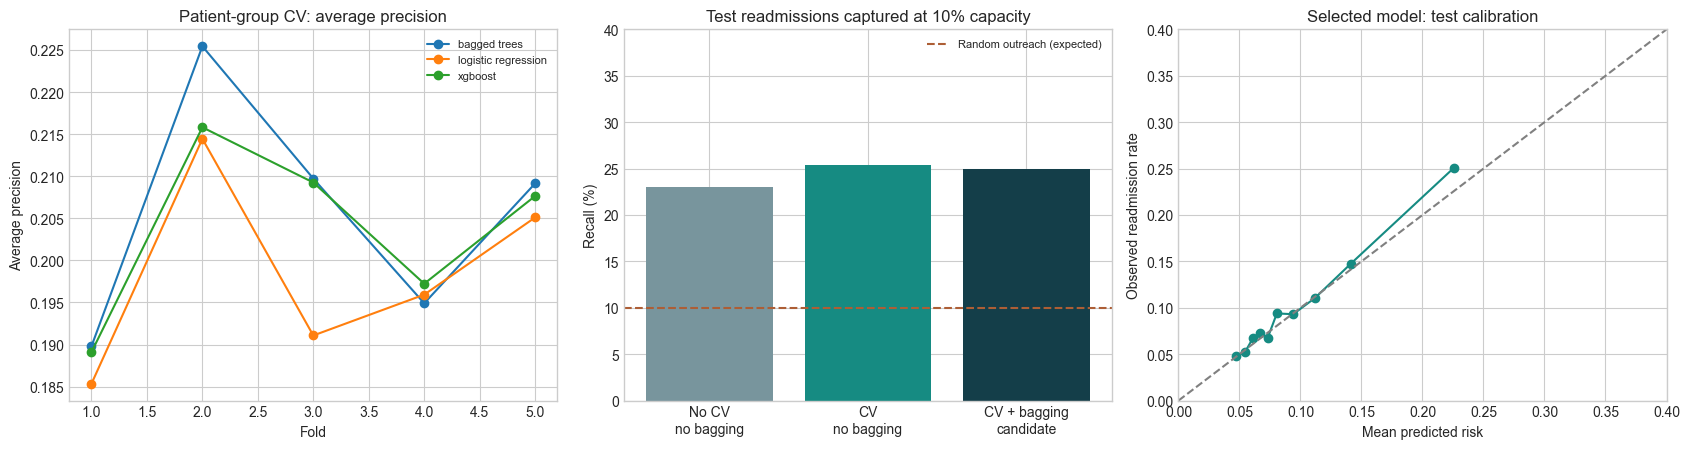

In [15]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for name, part in cv_rows.groupby("model"):
    axes[0].plot(part.fold, part.average_precision, marker="o", label=name.replace("_", " "))
axes[0].set(title="Patient-group CV: average precision", xlabel="Fold", ylabel="Average precision")
axes[0].legend(fontsize=8)
labels = ["No CV\nno bagging", "CV\nno bagging", "CV + bagging\ncandidate"]
axes[1].bar(labels, comparison.recall_at_capacity * 100, color=["#78959d", "#168b82", "#143e49"])
axes[1].axhline(10, linestyle="--", color="#ad5e35", label="Random outreach (expected)")
axes[1].set(title="Test readmissions captured at 10% capacity", ylabel="Recall (%)", ylim=(0, 40))
axes[1].legend(fontsize=8)
calibrated_rows = test_metrics["selected_calibrated"]["calibration"]
axes[2].plot([r["predicted"] for r in calibrated_rows], [r["observed"] for r in calibrated_rows], marker="o", color="#168b82")
axes[2].plot([0, .4], [0, .4], linestyle="--", color="gray")
axes[2].set(title="Selected model: test calibration", xlabel="Mean predicted risk", ylabel="Observed readmission rate", xlim=(0,.4), ylim=(0,.4))
fig.tight_layout()
fig.savefig(output_dir / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Inspect subgroup results
This uses one overall top-10% selection rule, rather than a separate threshold per group. Small groups are flagged. Race and sex were not inputs, but other features can still act as proxies; excluding those inputs does not establish fairness.

In [16]:
audit = pd.DataFrame(json.loads((output_dir / "subgroup_audit.json").read_text()))
display(audit[["attribute", "group", "n", "positives", "selection_rate", "recall_at_global_capacity", "small_group"]].round(4))

,attribute,group,n,positives,selection_rate,recall_at_global_capacity,small_group
0,age,[0-10),20,1,0.0000,0.0000,True
1,age,[10-20),103,11,0.0971,0.2727,True
2,age,[20-30),205,30,0.2390,0.5667,False
3,age,[30-40),480,53,0.1458,0.4151,False
4,age,[40-50),1241,135,0.1193,0.2741,False
5,age,[50-60),2011,177,0.0806,0.2542,False
6,age,[60-70),2533,264,0.0916,0.2348,False
7,age,[70-80),2688,248,0.0874,0.2218,False
8,age,[80-90),1420,150,0.1225,0.2067,False
9,age,[90-100),157,20,0.0382,0.0000,True


## 11. Check a real prediction request
The API uses the saved model and the same preprocessing as training. It requires the full feature contract and rejects patient IDs, outcomes, negative counts, and discharges outside the cohort. This in-process check verifies local serving behavior; it is not a cloud endpoint call.

In [17]:
from fastapi.testclient import TestClient
from readmission.serve import app
request = json.loads((output_dir / "sample_request.json").read_text())
display(pd.DataFrame(request["instances"]))
os.environ["MODEL_DIR"] = str(output_dir)
with TestClient(app) as client:
    response = client.post("/predict", json=request)
    assert response.status_code == 200, response.text
    print(json.dumps(response.json(), indent=2))

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age,admission_type_id,...,troglitazone,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
0,13,68,2,28,0,0,0,8,[80-90),2,...,No,No,Steady,No,No,No,No,No,Ch,Yes


{
  "predictions": [
    {
      "readmission_risk": 0.07870010809204599,
      "model": "bagged_trees"
    }
  ]
}


## 12. Next: execute the Google Cloud workflow
Open `02_gcp_workflow.ipynb` and `GCP_SETUP.md`. The cloud workflow loads the raw CSV into BigQuery, creates the same feature table using SQL, verifies parity, runs these models as a Vertex AI custom training job, deploys a prediction endpoint, records a successful request, and undeploys the model after the demo.

Current evidence supports **local predictive modeling and evaluation**. Claim BigQuery or Vertex AI execution only after the corresponding real jobs and endpoint evidence have been recorded.